# 02 — Merging Kogan and EDGAR-CORPUS

Kogan decides which reports are in the study and gives the volatility labels. EDGAR-CORPUS gives the text of Items 1, 1A and 7
for those reports. We match on company number (CIK) + filing year and measure how much data survives.

In [1]:
import gzip
import json
import re
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path("..")
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
kogan_dir = RAW / "kogan"
edgar_dir = PROCESSED / "edgar_matched"      # only the matched reports and the sections we use
for d in [kogan_dir, edgar_dir]:
    d.mkdir(parents=True, exist_ok=True)

YEARS = range(1996, 2007)
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"
EDGAR_URL = "https://huggingface.co/datasets/eloukas/edgar-corpus/resolve/main/{year}/{split}.jsonl"
SECTIONS = ["section_1", "section_1A", "section_7"]

MIN_WORDS = 100          # a section shorter than this counts as missing ("omitted", "see Exhibit 13", ...)
RATIO_RANGE = (0.5, 2)   # Kogan's and EDGAR's Item 7 'agree' if their lengths are within this range (an extraction check)
NAME_STOP = {"inc", "corp", "co", "ltd", "the", "of", "and", "company", "corporation", "group", "holdings",
             "holding", "international", "de", "new", "plc", "lp", "trust", "bancorp", "financial", "industries",
             "systems", "technologies", "american", "national", "first", "bank", "energy", "services"}
# ^ generic words ignored when looking for a company's name in its EDGAR text

## 1. Kogan: download and load all years

In [2]:
for y in YEARS:
    for f in ["meta.txt", "logvol.-12.txt", "logvol.+12.txt", "tok.tgz"]:
        target = kogan_dir / f"{y}.{f}"
        if not target.exists():
            urllib.request.urlretrieve(KOGAN_URL + target.name, target)

frames = []
for y in YEARS:
    meta = pd.read_csv(kogan_dir / f"{y}.meta.txt", sep="\t", header=None,
                       names=["key", "date", "url", "name", "cik"]).drop_duplicates("key")
    before = pd.read_csv(kogan_dir / f"{y}.logvol.-12.txt", sep=" ", header=None,
                         names=["logvol_before", "key"]).drop_duplicates("key")
    after = pd.read_csv(kogan_dir / f"{y}.logvol.+12.txt", sep=" ", header=None,
                        names=["logvol_after", "key"]).drop_duplicates("key")
    frames.append(meta.merge(before, on="key", how="left").merge(after, on="key", how="left").assign(year=y))
kogan = pd.concat(frames, ignore_index=True)
kogan["date"] = pd.to_datetime(kogan["date"].astype(str))

print("Kogan reports:", len(kogan))
print("filing year = folder year for all reports:", (kogan["date"].dt.year == kogan["year"]).all())
print("missing next-year label:", kogan["logvol_after"].isna().sum())
kogan["two_in_year"] = kogan.duplicated(["cik", "year"], keep=False)
print("reports sharing company + year with another report (can't be matched unambiguously):", kogan["two_in_year"].sum())

Kogan reports: 30465
filing year = folder year for all reports: True
missing next-year label: 0
reports sharing company + year with another report (can't be matched unambiguously): 190


- 30465 reports from the kogan dataset
- every report comes with the volatility of the stock for the next year
- there are 190 reports that share a company and year with another kogan report, we remove these entries entirely - small loss on data and keeps things simple.

Kogan's Item 7 word counts, used later to check each EDGAR match.

In [3]:
k7_file = PROCESSED / "kogan_item7_words.csv"
if k7_file.exists():
    k7 = pd.read_csv(k7_file)
else:
    rows = []
    for y in YEARS:
        with tarfile.open(kogan_dir / f"{y}.tok.tgz") as tar:
            for m in tar:
                if m.isfile():
                    rows.append((Path(m.name).name.split(".")[0], len(tar.extractfile(m).read().split())))
    k7 = pd.DataFrame(rows, columns=["key", "kogan_item7_words"]).drop_duplicates("key")
    k7.to_csv(k7_file, index=False)

kogan = kogan.drop(columns="kogan_item7_words", errors="ignore").merge(k7, on="key", how="left")
print("reports with no Kogan Item 7 text:", kogan["kogan_item7_words"].isna().sum())

reports with no Kogan Item 7 text: 0


## 2. Sourcing from the EDGAR dataset

In [4]:
# How big is EDGAR-CORPUS? 
def remote_size(url):
    req = urllib.request.Request(url, method="HEAD")
    with urllib.request.urlopen(req) as r:
        return int(r.headers["Content-Length"])

sizes = pd.DataFrame({split: {y: remote_size(EDGAR_URL.format(year=y, split=split)) for y in YEARS}
                      for split in ["train", "validate", "test"]}) / 1e9    # bytes -> GB
sizes["year total"] = sizes.sum(axis=1)
print(sizes.round(2).to_string())
print(f"average per year: {sizes['year total'].mean():.2f} GB | all {len(YEARS)} years: {sizes['year total'].sum():.1f} GB")

      train  validate  test  year total
1996   0.74      0.09  0.09        0.93
1997   0.86      0.10  0.11        1.07
1998   0.91      0.11  0.11        1.14
1999   0.92      0.12  0.12        1.15
2000   0.93      0.11  0.12        1.16
2001   0.97      0.12  0.12        1.21
2002   1.06      0.13  0.13        1.32
2003   1.04      0.13  0.13        1.30
2004   1.14      0.15  0.15        1.44
2005   1.21      0.16  0.16        1.54
2006   1.30      0.16  0.17        1.63
average per year: 1.26 GB | all 11 years: 13.9 GB


Each year is arppox 1.26 GB (train/validate/test files), approx 14 GB in total, too big to keep on disk. We instead read it line by line from Hugging Face and save only matched reports with Items 1, 1A and 7 (compressed). 

In [5]:
wanted = set(zip(kogan["cik"], kogan["year"]))
counts_file = edgar_dir / "edgar_counts.json"
edgar_counts = json.loads(counts_file.read_text()) if counts_file.exists() else {}

for y in YEARS:
    out = edgar_dir / f"{y}.jsonl.gz"
    if out.exists():
        continue
    tmp = edgar_dir / f"{y}.partial.gz"          # renamed only when the year is complete
    n_all = n_kept = 0
    with gzip.open(tmp, "wt") as f:
        for split in ["train", "validate", "test"]:
            with urllib.request.urlopen(EDGAR_URL.format(year=y, split=split)) as r:
                for line in r:
                    rec = json.loads(line)
                    n_all += 1
                    if (int(rec["cik"]), int(rec["year"])) in wanted:
                        f.write(json.dumps({"cik": int(rec["cik"]), "year": int(rec["year"]),
                                            **{s: rec[s] for s in SECTIONS}}) + "\n")
                        n_kept += 1
    tmp.rename(out)
    edgar_counts[str(y)] = n_all
    counts_file.write_text(json.dumps(edgar_counts))
    print(f"{y}: EDGAR has {n_all} 10-Ks, kept {n_kept}")

print("EDGAR 10-Ks per year:", edgar_counts)

EDGAR 10-Ks per year: {'1996': 9487, '1997': 10106, '1998': 10051, '1999': 9831, '2000': 9487, '2001': 8977, '2002': 8295, '2003': 8340, '2004': 8889, '2005': 8892, '2006': 8830}


In [6]:
# Company names from Kogan, to check each EDGAR text really belongs to that company
kogan_names = kogan.drop_duplicates(["cik", "year"]).set_index(["cik", "year"])["name"].to_dict()

def name_words(name):
    """Distinctive words of a company name: 'DELL INC' -> ['dell']."""
    return [w for w in re.findall(r"[a-z]+", name.lower().split("/")[0]) if w not in NAME_STOP and len(w) > 2]

rows = []
for y in YEARS:
    with gzip.open(edgar_dir / f"{y}.jsonl.gz", "rt") as f:
        for line in f:
            rec = json.loads(line)
            text = (rec["section_1"] + " " + rec["section_7"]).lower()
            words = name_words(kogan_names[(rec["cik"], rec["year"])])
            checkable = bool(words) and len(text.split()) >= 300     # too little text or no distinctive word: can't check
            rows.append({"cik": rec["cik"], "year": rec["year"],
                         "edgar_item1_words": len(rec["section_1"].split()),
                         "edgar_item1A_words": len(rec["section_1A"].split()),
                         "edgar_item7_words": len(rec["section_7"].split()),
                         "name_found": any(w in text for w in words) if checkable else np.nan})
edgar = pd.DataFrame(rows)
print("EDGAR reports kept:", len(edgar), "| duplicate company + year:", edgar.duplicated(["cik", "year"]).sum())

EDGAR reports kept: 28378 | duplicate company + year: 0


## 3. Merge and flag
We now check the quality of the merged dataset via the following flags:

- `matched`: EDGAR has a 10-K for that company and year (and Kogan has only one report for it)
- `has_item1` / `has_item1A`: that section has at least `MIN_WORDS` words
- `name_found`: the company's name from Kogan appears in EDGAR's Items 1 + 7 (**the match check**; blank if there's too little text to check)
- `item7_lengths_agree`: EDGAR's Item 7 is 0.5–2× the length of Kogan's. Not a match check: it flags reports where one of the two *extractions* of Item 7 has gone wrong
- `usable`: has a label + matched + has Item 1 (Item 7 comes from Kogan)

In [7]:
df = kogan.merge(edgar, on=["cik", "year"], how="left")
df["matched"] = df["edgar_item7_words"].notna() & ~df["two_in_year"]
df["has_label"] = df["logvol_after"].notna()
df["has_item1"] = df["matched"] & (df["edgar_item1_words"] >= MIN_WORDS)
df["has_item1A"] = df["matched"] & (df["edgar_item1A_words"] >= MIN_WORDS)
df["item7_ratio"] = df["edgar_item7_words"] / df["kogan_item7_words"]
df["item7_lengths_agree"] = df["matched"] & df["item7_ratio"].between(*RATIO_RANGE)
df["usable"] = df["has_label"] & df["has_item1"]

flags = ["matched", "has_item1", "has_item1A", "item7_lengths_agree", "usable"]
summary = df.groupby("year")[flags].sum()
summary.insert(0, "kogan_reports", df.groupby("year").size())
summary.loc["all"] = summary.sum()
percent = summary[flags].div(summary["kogan_reports"], axis=0).mul(100).round(1).add_suffix(" %")
pd.concat([summary, percent], axis=1)

,kogan_reports,matched,has_item1,has_item1A,item7_lengths_agree,usable,matched %,has_item1 %,has_item1A %,item7_lengths_agree %,usable %
year,,,,,,,,,,,
1996,1406,1336,1258,7,1172,1258,95.0,89.5,0.5,83.4,89.5
1997,2260,2067,1976,12,1843,1976,91.5,87.4,0.5,81.5,87.4
1998,2461,2244,2142,11,2020,2142,91.2,87.0,0.4,82.1,87.0
1999,2524,2314,2220,11,2109,2220,91.7,88.0,0.4,83.6,88.0
2000,2424,2240,2151,9,2055,2151,92.4,88.7,0.4,84.8,88.7
2001,2596,2388,2299,19,2197,2299,92.0,88.6,0.7,84.6,88.6
2002,2845,2688,2587,18,2439,2587,94.5,90.9,0.6,85.7,90.9
2003,3611,3340,3217,25,2972,3217,92.5,89.1,0.7,82.3,89.1
2004,3558,3309,3168,26,2951,3168,93.0,89.0,0.7,82.9,89.0


- consitent across years
- item 1A is lacking before 2005, before this point, this section was not a mandatory section of the report
- usable = label + match + item 1, doesn't need item 7 lengths to agree (see section 5)

## 4. Is it the same company?

In [8]:
checked = df.loc[df["matched"], "name_found"].dropna().astype(bool)
print(f"matched reports we could check: {len(checked)} of {df['matched'].sum()}")
print(f"company name found in EDGAR text: {checked.mean():.1%}")
print(df.loc[df["matched"]].groupby("year")["name_found"].mean().mul(100).round(1).rename("name found %").to_string())

matched reports we could check: 27787 of 28286
company name found in EDGAR text: 98.9%
year
1996    97.9
1997    98.4
1998    98.5
1999    98.6
2000    98.8
2001    99.0
2002    99.0
2003    99.4
2004    99.2
2005    99.3
2006    98.8


The name is found in 98.9% of the checkable reports. The remaining 1.1% is likely due to difference spellings e.g. "Applebee's" vs "APPLEBEES".

In [9]:
# Names not found, to look at by hand: real mismatches, or just a different spelling ("Applebee's" vs "APPLEBEES")?
df.loc[df["name_found"] == False, ["year", "name", "cik", "kogan_item7_words", "edgar_item7_words"]].sample(15, random_state=0)

,year,name,cik,kogan_item7_words,edgar_item7_words
29648,2006,RELIANT ENERGY INC,1126294,11658,6374.0
10736,2000,SUPERIOR ENERGY SERVICES INC,886835,2533,2482.0
29685,2006,ROBBINS & MYERS INC,84290,5840,4683.0
19862,2003,USFREIGHTWAYS CORP,881791,6752,4029.0
3208,1997,SCHLOTZSKYS INC,1002178,5758,5100.0
27843,2006,COLUMBUS MCKINNON CORP,1005229,7628,6352.0
1044,1996,RCM TECHNOLOGIES INC,700841,1653,53.0
13321,2001,TB WOODS CORP,1000227,1962,2794.0
15515,2002,OCEAN BIO CHEM INC,350737,1061,1276.0
23005,2004,SKYLINE CORP,90896,2557,1953.0


## 5. Do the two Item 7 extractions agree?

matched reports: 28286
ratio EDGAR / Kogan words, quantiles:
0.05    0.31
0.10    0.53
0.25    0.81
0.50    0.94
0.75    1.04
0.90    1.29
0.95    1.53
EDGAR Item 7 under 100 words (missing): 2.6%
ratio below 0.5: 9.2% | above 2: 2.4%


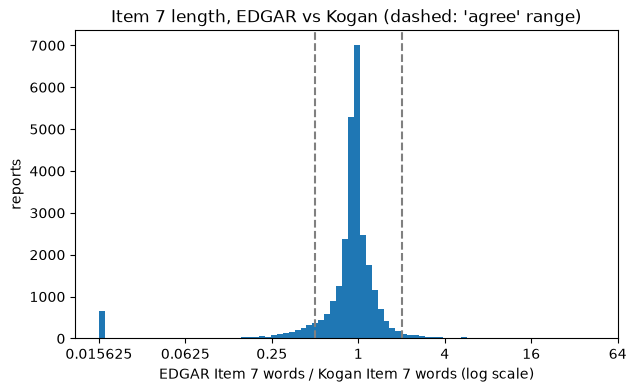

In [10]:
r = df.loc[df["matched"], "item7_ratio"]
print("matched reports:", len(r))
print("ratio EDGAR / Kogan words, quantiles:")
print(r.quantile([0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]).round(2).to_string())
print(f"EDGAR Item 7 under {MIN_WORDS} words (missing): {(df.loc[df['matched'], 'edgar_item7_words'] < MIN_WORDS).mean():.1%}")
print(f"ratio below {RATIO_RANGE[0]}: {(r < RATIO_RANGE[0]).mean():.1%} | above {RATIO_RANGE[1]}: {(r > RATIO_RANGE[1]).mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(np.log2(r.clip(1 / 64, 64)), bins=80)
for edge in RATIO_RANGE:
    ax.axvline(np.log2(edge), color="grey", ls="--")
ax.set_xticks(range(-6, 7, 2), [f"{2.0 ** k:g}" for k in range(-6, 7, 2)])
ax.set_xlabel("EDGAR Item 7 words / Kogan Item 7 words (log scale)")
ax.set_ylabel("reports")
ax.set_title("Item 7 length, EDGAR vs Kogan (dashed: 'agree' range)")
plt.show()

In [11]:
# Read the start of each version for the most extreme cases in each direction
def show(row, n=200):
    with gzip.open(edgar_dir / f"{row.year}.jsonl.gz", "rt") as f:
        edgar7 = next(json.loads(l)["section_7"] for l in f if json.loads(l)["cik"] == row.cik)
    with tarfile.open(kogan_dir / f"{row.year}.tok.tgz") as tar:
        m = next(m for m in tar if m.isfile() and Path(m.name).name.startswith(row.key))
        kogan7 = tar.extractfile(m).read().decode("utf-8", "replace")
    print(f"=== {row.name} ({row.year}) | Kogan {row.kogan_item7_words} words, EDGAR {row.edgar_item7_words:.0f} words")
    print("  KOGAN:", " ".join(kogan7.split()[:n // 5]))
    print("  EDGAR:", " ".join(edgar7.split()[:n // 5]), "\n")

ok = df[df["matched"] & (df["edgar_item7_words"] >= MIN_WORDS)]
print("##### EDGAR much LONGER than Kogan")
for row in ok.nlargest(2, "item7_ratio").itertuples():
    show(row)
print("##### EDGAR much SHORTER than Kogan")
for row in ok.nsmallest(2, "item7_ratio").itertuples():
    show(row)

##### EDGAR much LONGER than Kogan


=== BRISTOL MYERS SQUIBB CO (2006) | Kogan 1024 words, EDGAR 32173 words
  KOGAN: item # management s discussion and analysis of financial condition and results of operations outlook below in addition to patents and regulatory forms of exclusivity the company also holds intellectual property in the form of trademarks on products such as
  EDGAR: Item 7. MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND RESULTS OF OPERATIONS. EXECUTIVE SUMMARY About the Company Bristol-Myers Squibb Company (BMS, the Company or Bristol-Myers Squibb) is a worldwide pharmaceutical and related health care products company whose mission is 



=== MONSANTO CO /NEW/ (2005) | Kogan 1345 words, EDGAR 33437 words
  KOGAN: item # management s discussion and analysis of financial condition and results of operations for information regarding the factors that have affected or may affect the comparability of our business results in july # monsanto s board of directors approved
  EDGAR: ITEM 7. MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND RESULTS OF OPERATIONS OVERVIEW Background Monsanto Company, along with its subsidiaries, is a global provider of agricultural products for farmers. We produce leading seed brands, including DEKALB, Asgrow, Seminis and 

##### EDGAR much SHORTER than Kogan


=== MICROTUNE INC (2006) | Kogan 23794 words, EDGAR 113 words
  KOGAN: item # management s discussion and analysis of financial condition and results of operations for discussions of net revenue by product group technology intellectual property research and development we were founded in # on a commitment to rf ic innovation
  EDGAR: ITEM 7. MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND RESULTS OF OPERATIONS NOTE: For a more complete understanding of our financial condition and results of operations, and some of the risks that could affect our future results, see “Risk 



=== NORTHEAST UTILITIES (2005) | Kogan 25955 words, EDGAR 137 words
  KOGAN: item # managements discussion and analysis of financial condition and results of operations quot nbsp # financing requirements the nu systems aggregate capital requirements for # are approximately as follows nbsp nbsp nbsp nbsp nbsp nbsp nbsp nbsp nbsp nbsp
  EDGAR: Item 7. Management's Discussion and Analysis of Financial Condition and Results of Operations NU. Reference is made to information under the heading "Management's Discussion and Analysis and Results of Operations" contained within NU's 2005 Annual Report to Shareholders, which information 



- lengths agree for 82% of reports, median ratio 0.94
- disagreements are bad extractions, not bad matches (names check out, section 4)
- kogan sometimes starts at a cross-reference and grabs the wrong section, e.g. bristol-myers squibb
- edgar sometimes nearly empty as item 7 is "incorporated by reference", e.g. northeast utilities
- so neither source is always right, and the paper's own item 7 has these errors
- need to chose which item 7 to use for finbert (paper reproduction must use kogan's)

## 6. Bias check: are the reports we lose different?

Its worth checking if there is some form of survivorship bias in our process. It seems reasonable that there could be correlation between volatility and completeness/availability of SEC filings.

In [12]:
def compare(flag):
    keep = df.loc[df[flag] & df["has_label"], "logvol_after"]
    lose = df.loc[~df[flag] & df["has_label"], "logvol_after"]
    t = stats.ttest_ind(keep, lose, equal_var=False)
    return pd.Series({"kept": len(keep), "lost": len(lose),
                      "mean logvol kept": keep.mean(), "mean logvol lost": lose.mean(),
                      "lost more volatile by %": 100 * (np.exp(lose.mean() - keep.mean()) - 1),
                      "p-value": t.pvalue})

pd.DataFrame({flag: compare(flag) for flag in ["matched", "usable"]}).round(3)

,matched,usable
kept,28286.000,27142.000
lost,2179.000,3323.000
mean logvol kept,-3.438,-3.433
mean logvol lost,-3.402,-3.451
lost more volatile by %,3.645,-1.763
p-value,0.088,0.248


In [13]:
by_year = df[df["has_label"]].groupby(["year", "usable"])["logvol_after"].mean().unstack()
by_year.columns = ["lost", "kept"]
by_year["lost more volatile by %"] = (100 * (np.exp(by_year["lost"] - by_year["kept"]) - 1)).round(1)
by_year.round(3)

,lost,kept,lost more volatile by %
year,,,
1996,-3.483,-3.444,-3.9
1997,-3.467,-3.357,-10.5
1998,-3.351,-3.139,-19.1
1999,-3.168,-3.096,-7.0
2000,-3.086,-3.054,-3.1
2001,-3.015,-3.199,20.2
2002,-3.179,-3.236,5.9
2003,-3.504,-3.548,4.4
2004,-3.743,-3.700,-4.2


These results are reassuring. The fact the the percentages above oscillate around zero implies this is noise. The materiality of the gap is also small. We dont reach a 5% significance level and thus are happy to proceed.

## 7. Save
One row per Kogan report with the flags and word counts (no text). The texts stay in `data/processed/edgar_matched/`.

In [14]:
out = PROCESSED / "kogan_edgar_merged.csv"
df.drop(columns=["url"]).to_csv(out, index=False)
print("saved", out, df.shape)

saved ../data/processed/kogan_edgar_merged.csv (30465, 21)


## Conclusion
- keep 27,142 of 30,465 reports (89%), 87-91% every year
- match checked: name found in 98.9% of reports
- no meaningful bias in what we lose (p = 0.09 and 0.25), unlike yahoo (26% kept, lost firms 23% more volatile)
- item 1A only usable for 2005-06
- to decide: kogan or edgar item 7 for finbert